# Colombian politics

In [18]:
import numpy as np
import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from networkx.algorithms.community import greedy_modularity_communities
from IPython.display import display
import networkx as nx
import numpy as np
import pandas as pd
import pickle
import time
from tqdm.auto import tqdm
import blockdynamicnetworks as bdn
import numpy as np
import networkx as nx
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import time
import blockdynamicnetworks as bdn
import numpy as np
import pickle
import time
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2,
    "lines.markersize": 7,
    "text.usetex": False})

## Load and visualize network

In [ ]:

EXCEL_FILE = r"raw_data_colombian_politics.xlsx"
SHEET = 1  # Sheet name or index

# LOAD DATA
df = pd.read_excel(EXCEL_FILE, sheet_name=SHEET)
# df = df.drop_duplicates(subset=["NOMBRE"])

print("Dataset dimensions:", df.shape)


# COLUMNS REPRESENTING POLITICAL POSITIONS
columns_to_exclude = [
    "NOMBRE", "EDAD", "GENERO",
    "PARTIDO_POLITICO", "NIVEL_DE_ESTUDIOS", "UNIVERSIDAD",
    "CARRERA", "PREDECESORES", "GOBERNACION",
    "FLAG_MINISTERIO", "FLAG_VIVO"
]

position_columns = []

for col in df.columns:
    if col in columns_to_exclude:
        continue

    values = set(df[col].dropna().unique())

    # Detect binary columns
    if values.issubset({0, 1}):
        position_columns.append(col)

print("\nDetected political position columns:")
print(position_columns)


# CREATE BIPARTITE GRAPH
B = nx.Graph()

# ADD PERSON NODES
for _, row in df.iterrows():
    name = row["NOMBRE"]

    B.add_node(
        name,
        bipartite="person",
        type="person",
        age=row.get("EDAD"),
        gender=row.get("GENERO"),
        political_party=row.get("PARTIDO_POLITICO"),
        education_level=row.get("NIVEL_DE_ESTUDIOS"),
        university=row.get("UNIVERSIDAD"),
        degree=row.get("CARRERA"),
        predecessors=row.get("PREDECESORES"),
        governorship=row.get("GOBERNACION"),
        ministry_flag=row.get("FLAG_MINISTERIO"),
        alive_flag=row.get("FLAG_VIVO")
    )


# ADD POLITICAL POSITION NODES
for position in position_columns:
    B.add_node(position, bipartite="position", type="position")


# ADD PERSON-POSITION EDGES
for _, row in df.iterrows():
    name = row["NOMBRE"]

    for position in position_columns:
        if row[position] == 1:
            B.add_edge(name, position, relationship="holds")


print("\n================================")
print("BIPARTITE GRAPH CREATED")
print("Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())


# SEPARATE BIPARTITE NODE SETS
persons = {
    node for node, data in B.nodes(data=True)
    if data["type"] == "person"
}

positions = {
    node for node, data in B.nodes(data=True)
    if data["type"] == "position"
}

print("\nNumber of persons:", len(persons))
print("Number of political positions:", len(positions))


# PERSON-PERSON PROJECTION
from networkx.algorithms import bipartite

G_persons = bipartite.weighted_projected_graph(B, persons)

print("\n================================")
print("PERSON-PERSON PROJECTION")
print("Nodes:", G_persons.number_of_nodes())
print("Edges:", G_persons.number_of_edges())

Dataset dimensions: (265, 62)

Detected political position columns:
['PRESIDENCIA', 'VICEPRESIDENCIA', 'SUBDIRECTOR_DAPRE', 'VIC_VIVIENDA', 'VIC_TRANSPORTE', 'VIC_SALUD', 'VIC_ENERGIA', 'VIC_JUSTICIA', 'VIC_INTERIOR', 'VIC_HACIENDA', 'VIC_EDUCACION', 'VIC_DEPORTE', 'VIC_DEFENSA', 'VIC_COMERCIO', 'VIC_AMBIENTE', 'VIC_TIC', 'VIC_TRABAJO', 'VIC_IGUALDAD', 'VIC_CULTURA', 'VIC_CIENCIAS', 'VIC_CANCILLERIA', 'VIC_AGRICULTURA', 'DAPRE_.DEPARTAMENTO_ADMINISTRATIVO_DE_LA_PRESIDENCIA.', 'AGRICULTURA', 'AMBIENTE', 'CANCILLERIA', 'CIENCIAS', 'COMERCIO', 'CULTURA', 'DEFENSA', 'DEPORTE', 'EDUCACION', 'HACIENDA', 'IGUALDAD', 'INTERIOR', 'JUSTICIA', 'ENERGIA', 'SALUD', 'TIC', 'TRABAJO', 'TRANSPORTE', 'VIVIENDA', 'DANE', 'DPN', 'PRESID_SENADO', 'PRESID_CAMARA_REPRESENTANTES', 'PROSPERIDAD_SOCIAL', 'DIAN', 'JEFE_DESPACHO_PRESIDENCIAL', 'SUPER_INTENDENCIA_INDUS_COMER']

BIPARTITE GRAPH CREATED
Nodes: 314
Edges: 379

Number of persons: 264
Number of political positions: 50

PERSON-PERSON PROJECTION
Nodes: 

In [62]:


# ============================================================
# 1. GENERAL NETWORK STATISTICS
# ============================================================

network_statistics = []

def add_statistic(category, metric, value):
    network_statistics.append({
        "Category": category,
        "Metric": metric,
        "Value": value
    })


# Dataset
add_statistic("Dataset", "Number of records", len(df))
add_statistic("Dataset", "Number of variables", len(df.columns))

# Bipartite network
add_statistic("Bipartite network", "Total nodes", B.number_of_nodes())
add_statistic("Bipartite network", "Total edges", B.number_of_edges())
add_statistic("Bipartite network", "Number of persons", len(persons))
add_statistic("Bipartite network", "Number of political positions", len(positions))

# Person-person projection
add_statistic("Person network", "Number of nodes", G_persons.number_of_nodes())
add_statistic("Person network", "Number of edges", G_persons.number_of_edges())

# Density
add_statistic(
    "Person network",
    "Network density",
    nx.density(G_persons)
)

# Average degree
degrees = dict(G_persons.degree())

add_statistic(
    "Person network",
    "Average degree",
    np.mean(list(degrees.values()))
)

# Degree standard deviation
add_statistic(
    "Person network",
    "Degree standard deviation",
    np.std(list(degrees.values()), ddof=1)
)

# Average clustering coefficient
add_statistic(
    "Person network",
    "Average clustering coefficient",
    nx.average_clustering(G_persons)
)

# Connected components
components = list(nx.connected_components(G_persons))

add_statistic(
    "Person network",
    "Number of connected components",
    len(components)
)

add_statistic(
    "Person network",
    "Largest connected component",
    max(map(len, components), default=0)
)

# Isolated nodes
add_statistic(
    "Person network",
    "Isolated nodes",
    nx.number_of_isolates(G_persons)
)

# Average shortest path in the largest connected component
if components:
    largest_component = G_persons.subgraph(
        max(components, key=len)
    )

    if len(largest_component) > 1:
        add_statistic(
            "Person network",
            "Average shortest path (largest component)",
            nx.average_shortest_path_length(largest_component)
        )

# Display table
network_summary = pd.DataFrame(network_statistics)

network_summary["Value"] = network_summary["Value"].apply(
    lambda x: round(x, 4) if isinstance(x, (int, float, np.number)) else x
)

display(network_summary)

,Category,Metric,Value
0,Dataset,Number of records,265.0000
1,Dataset,Number of variables,62.0000
2,Bipartite network,Total nodes,314.0000
3,Bipartite network,Total edges,379.0000
4,Bipartite network,Number of persons,264.0000
5,Bipartite network,Number of political positions,50.0000
6,Person network,Number of nodes,264.0000
7,Person network,Number of edges,2014.0000
8,Person network,Network density,0.0580
9,Person network,Average degree,15.2576


C:\Users\carlo\AppData\Local\Temp\ipykernel_9016\3098555089.py:297: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


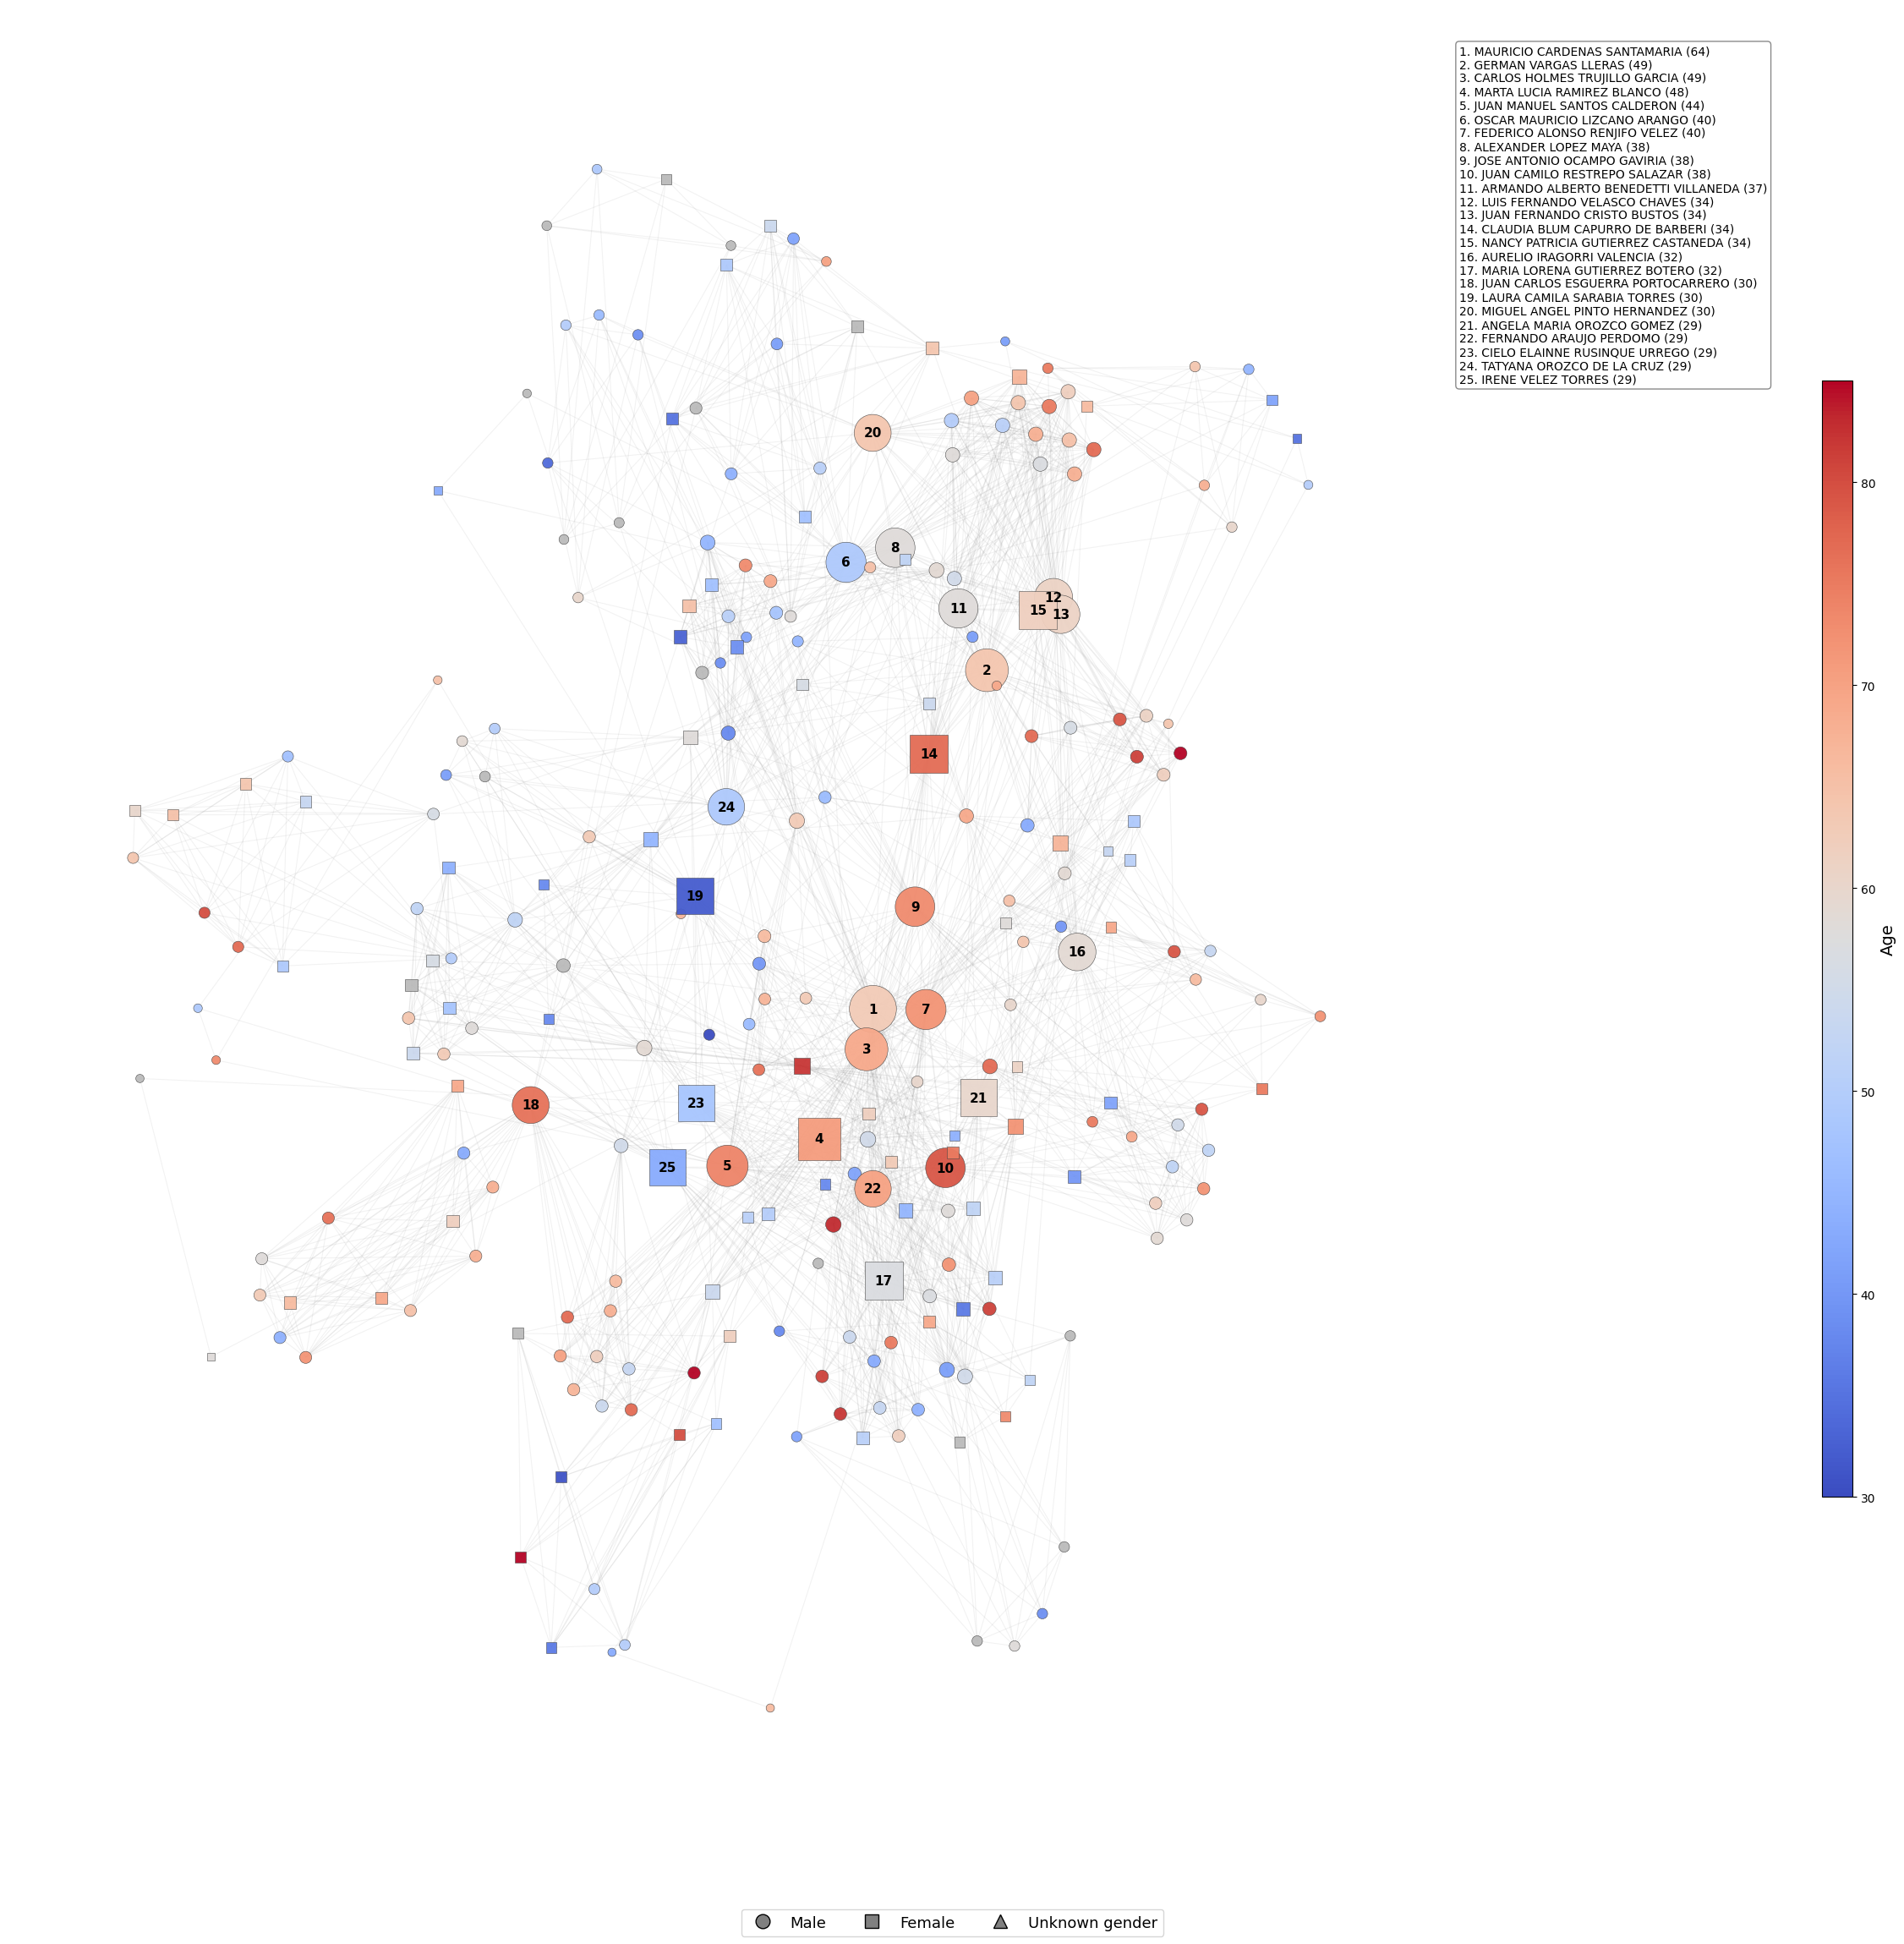

In [ ]:
# VISUALIZATION OF G_persons

gender_dict = dict(
    zip(df["NOMBRE"], df["GENERO"])
)

age_dict = dict(
    zip(df["NOMBRE"], df["EDAD"])
)

governorship_dict = dict(
    zip(df["NOMBRE"], df["GOBERNACION"])
)


# COMPUTE NODE DEGREES
degrees = dict(G_persons.degree())

top_n = 25

top_nodes = sorted(
    degrees.items(),
    key=lambda x: x[1],
    reverse=True
)[:top_n]

top_names = [x[0] for x in top_nodes]


# AGE COLOR NORMALIZATION
valid_ages = [
    age_dict[n]
    for n in G_persons.nodes()
    if pd.notna(age_dict.get(n))
]

norm = mcolors.Normalize(
    vmin=min(valid_ages),
    vmax=max(valid_ages)
)

cmap = cm.coolwarm


# COMPUTE NETWORK LAYOUT
pos = nx.spring_layout(
    G_persons,
    k=2.995,
    iterations=400,
    seed=42
)


# CREATE FIGURE
fig, ax = plt.subplots(
    figsize=(24, 24)
)

# fig.patch.set_facecolor("#f4f4f4")
# ax.set_facecolor("#f4f4f4")


# DRAW NETWORK EDGES
nx.draw_networkx_edges(
    G_persons,
    pos,
    ax=ax,
    alpha=0.10,
    width=0.8,
    edge_color="gray"
)


# CLASSIFY NODES BY GENDER
men = []
women = []
others = []

for n in G_persons.nodes():

    gender = str(
        gender_dict.get(n, "")
    ).upper()

    if gender.startswith("M"):
        men.append(n)

    elif gender.startswith("F"):
        women.append(n)

    else:
        others.append(n)


# ASSIGN NODE COLORS BASED ON AGE
color_map = {}

for n in G_persons.nodes():

    age = age_dict.get(n)

    if pd.isna(age):
        color_map[n] = "#BBBBBB"

    else:
        color_map[n] = cmap(norm(age))


# ASSIGN NODE SIZES BASED ON DEGREE
node_sizes = {}

for n in G_persons.nodes():

    degree = degrees[n]

    if n in top_names:
        node_sizes[n] = 450 + degree * 18

    else:
        node_sizes[n] = 40 + degree * 5


# DRAW MALE NODES
nx.draw_networkx_nodes(
    G_persons,
    pos,
    nodelist=men,
    node_shape="o",
    node_size=[
        node_sizes[n]
        for n in men
    ],
    node_color=[
        color_map[n]
        for n in men
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


# DRAW FEMALE NODES
nx.draw_networkx_nodes(
    G_persons,
    pos,
    nodelist=women,
    node_shape="s",
    node_size=[
        node_sizes[n]
        for n in women
    ],
    node_color=[
        color_map[n]
        for n in women
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


# DRAW NODES WITH UNKNOWN GENDER
nx.draw_networkx_nodes(
    G_persons,
    pos,
    nodelist=others,
    node_shape="^",
    node_size=[
        node_sizes[n]
        for n in others
    ],
    node_color=[
        color_map[n]
        for n in others
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


# LABEL TOP 25 NODES
labels = {}

top_nodes_legend = []

for idx, (node, degree) in enumerate(top_nodes, start=1):

    labels[node] = str(idx)

    top_nodes_legend.append(
        f"{idx}. {node} ({degree})"
    )

nx.draw_networkx_labels(
    G_persons,
    pos,
    labels=labels,
    font_size=11,
    font_weight="bold",
    font_color="black",
    ax=ax
)


# ADD TOP NODES LEGEND
legend_text = "\n".join(top_nodes_legend)

ax.text(
    1.01,
    0.98,
    legend_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray",
        alpha=0.92
    )
)


# ADD AGE COLORBAR
sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar_ax = fig.add_axes(
    [0.90, 0.22, 0.015, 0.55]
)

cbar = fig.colorbar(
    sm,
    cax=cbar_ax
)

cbar.set_label(
    "Age",
    fontsize=14
)


# CREATE GENDER LEGEND
legend_elements = [

    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Male",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker="s",
        color="w",
        label="Female",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker="^",
        color="w",
        label="Unknown gender",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=12
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=13
)


# FINAL FORMATTING
ax.axis("off")

plt.tight_layout(
    rect=[0, 0.03, 0.88, 0.96]
)
plt.savefig(
    "Network_Colombian_Politics.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

In [10]:
G_real = nx.Graph()
G_real.add_nodes_from(G_persons.nodes(data=True))
for u, v, data in G_persons.edges(data=True):
    if u == v:
        continue
    G_real.add_edge(u, v, weight=1)

import community as community_louvain  # python-louvain

partition_louvain = community_louvain.best_partition(
    G_real,
    weight="weight",
    random_state=123
)

labels_louvain = [
    partition_louvain[node]
    for node in G_real.nodes()
]

z0 = bdn.Partition(labels_louvain)

print("\nInitial partition - Louvain")

print("Number of nodes:", z0.size())
print("Number of communities:", z0.number_of_communities())
print("Community sizes:", z0.community_sizes())
print("Labels:", z0.labels())


Initial partition - Louvain
Number of nodes: 264
Number of communities: 13
Community sizes: [39, 15, 28, 11, 34, 40, 14, 12, 31, 16, 10, 7, 7]
Labels: [0, 1, 1, 2, 3, 0, 4, 5, 6, 7, 1, 5, 2, 5, 8, 0, 1, 0, 3, 2, 4, 2, 3, 9, 5, 4, 4, 1, 4, 6, 1, 4, 8, 2, 9, 4, 5, 0, 7, 1, 6, 4, 2, 9, 10, 8, 4, 4, 0, 5, 4, 8, 0, 0, 7, 10, 5, 8, 5, 10, 8, 7, 8, 0, 5, 0, 5, 0, 0, 6, 5, 10, 0, 7, 10, 2, 8, 5, 5, 10, 7, 4, 2, 0, 4, 2, 4, 9, 4, 4, 0, 11, 8, 2, 8, 6, 4, 2, 12, 0, 5, 2, 9, 8, 5, 3, 12, 8, 3, 11, 11, 4, 6, 0, 2, 2, 9, 4, 1, 6, 4, 7, 1, 4, 9, 5, 6, 0, 5, 2, 8, 5, 3, 8, 5, 7, 1, 9, 5, 0, 1, 0, 0, 11, 10, 4, 8, 2, 9, 6, 8, 11, 8, 2, 3, 4, 9, 5, 3, 6, 5, 5, 5, 9, 12, 5, 11, 5, 1, 5, 5, 12, 8, 7, 4, 8, 12, 10, 0, 2, 0, 2, 8, 4, 6, 0, 4, 8, 0, 8, 4, 9, 4, 5, 2, 8, 5, 1, 0, 0, 4, 8, 2, 1, 7, 4, 0, 0, 6, 2, 9, 5, 4, 5, 10, 9, 7, 4, 2, 0, 3, 8, 5, 0, 0, 5, 2, 8, 3, 2, 0, 10, 0, 0, 0, 4, 2, 6, 7, 8, 12, 8, 5, 5, 8, 0, 2, 0, 9, 4, 8, 12, 5, 1, 5, 5, 8, 3, 9, 5, 0, 2, 6, 11]


## Prior elictation

In [11]:

from scipy.optimize import brentq
from scipy.special import gammaln
from scipy.stats import poisson

def rising_log(a, n):
    return gammaln(a + n) - gammaln(a)
def expected_K_DP(n, alpha):
    i = np.arange(n)
    return np.sum(alpha / (alpha + i))
def calibrate_DP(n, K_target):
    return brentq(lambda alpha: expected_K_DP(n, alpha) - K_target,1e-8,1e6)
def expected_K_PY(n, alpha, sigma):
    i = np.arange(n)
    return np.sum((alpha + sigma * i) / (alpha + i))
def calibrate_PY(n, K_target, sigma=0.1):
    lower = -sigma + 1e-8
    K_min = expected_K_PY(n, lower, sigma)
    K_max = expected_K_PY(n, 1e6, sigma)
    if not (K_min <= K_target <= K_max):
        raise ValueError(f"PY: Not possible with sigma={sigma}. "
            f"Approximate range of E[K] is [{K_min:.4f}, {K_max:.4f}].")
    return brentq(lambda alpha: expected_K_PY(n, alpha, sigma) - K_target,lower,1e6)
def expected_K_DM(n, beta, H):
    log_p_empty = rising_log((H - 1) * beta, n)- rising_log(H * beta, n)
    return H * (1 - np.exp(log_p_empty))
def calibrate_DM(n, K_target, H):
    return brentq(lambda beta: expected_K_DM(n, beta, H) - K_target,1e-8,1e5)
def expected_K_MFM(n, rho, p_k):
    p_k = np.asarray(p_k, dtype=float)
    p_k = p_k / p_k.sum()
    M_values = np.arange(1, len(p_k) + 1)
    expected = 0.0
    for M, pM in zip(M_values, p_k):
        if pM == 0:
            continue
        log_p_empty = rising_log((M - 1) * rho, n)- rising_log(M * rho, n)
        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional
    return expected
def calibrate_MFM(n, K_target, p_k):
    max_K = len(p_k)
    return brentq(lambda rho: expected_K_MFM(n, rho, p_k) - K_target,1e-8,1e5)
def expected_K_PCPP(n, theta, omega, tol=1e-10):
    M_max = int(poisson.ppf(1 - tol, theta)) + 1
    M_values = np.arange(1, M_max + 1)
    probabilities = poisson.pmf(M_values - 1, theta)
    probabilities /= probabilities.sum()
    expected = 0.0
    for M, pM in zip(M_values, probabilities):
        if M == 1:
            expected_conditional = 1.0
            expected += pM * expected_conditional
            continue
        if omega == 0:
            log_p_empty = n * np.log((M - 1) / M)
        else:
            alpha_M = M / (omega**2) - 1 / M
            log_p_empty = rising_log((M - 1) * alpha_M, n) - rising_log(M * alpha_M, n)
        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional
    return expected
def calibrate_PCPP(n, K_target, omega=0.0, tol=1e-10):
    def objective(theta):
        return expected_K_PCPP(n, theta, omega, tol) - K_target
    return brentq(objective, 1e-8, 1e4)
def simulate_GN_partition(n, gamma, seed=None):
    rng = np.random.default_rng(seed)
    prior = bdn.PartitionPrior(bdn.PriorType.GN,gamma)
    labels = [0]
    for i in range(1, n):
        current = bdn.Partition(labels)
        K = len(set(labels))
        candidates = []
        for k in range(K):
            new_labels = labels.copy()
            old_label = sorted(set(labels))[k]
            new_labels.append(old_label)
            candidates.append(new_labels)
        new_labels = labels.copy()
        new_labels.append(max(labels) + 1)
        candidates.append(new_labels)
        log_probs = np.array([prior.log_probability(bdn.Partition(candidate)) for candidate in candidates])
        log_probs -= np.max(log_probs)
        probs = np.exp(log_probs)
        probs /= probs.sum()
        chosen = rng.choice(len(candidates), p=probs)
        labels = candidates[chosen]
    return len(set(labels))
def expected_K_GN_MC(n, gamma, simulations=200, seed=123):
    values = [simulate_GN_partition(n,gamma,seed=seed + s) for s in range(simulations)]
    return np.mean(values)
def calibrate_GN_MC(n, K_target, simulations=200, seed=123):
    gamma_grid = np.linspace(0.1, 0.9, 11)
    results = []
    for gamma in gamma_grid:
        K_est = expected_K_GN_MC(n,gamma,simulations=simulations,seed=seed)
        results.append((gamma, K_est))
    best_gamma, best_K = min(results,key=lambda x: abs(x[1] - K_target))
    return best_gamma, best_K, results

In [ ]:
K_target = 15
n = 264
alpha_DP = calibrate_DP(n, K_target)
sigma_PY = 0.01
alpha_PY = calibrate_PY(n,K_target,sigma=sigma_PY)
H_DM = 30
beta_DM = calibrate_DM(n,K_target,H=H_DM)
p_k_MFM = np.ones(30) / 30
rho_MFM = calibrate_MFM(n,K_target,p_k=p_k_MFM)
gamma_GN, K_GN_est, GN_results = calibrate_GN_MC(n,K_target,simulations=100)
omega_PCPP = 0.5
theta_PCPP = calibrate_PCPP(n,K_target,omega=omega_PCPP)
print("Objective E[K] =", K_target)
print("\nDP")
print("alpha =", alpha_DP)
print("E[K] =", expected_K_DP(n, alpha_DP))
print("\nPY")
print("alpha =", alpha_PY)
print("sigma =", sigma_PY)
print("E[K] =", expected_K_PY(n, alpha_PY, sigma_PY))
print("\nDM")
print("beta =", beta_DM)
print("H =", H_DM)
print("E[K] =", expected_K_DM(n, beta_DM, H_DM))
print("\nMFM")
print("rho =", rho_MFM)
print("E[K] =", expected_K_MFM(n, rho_MFM, p_k_MFM))
print("\nGN")
print("gamma =", gamma_GN)
print("E[K] estimated by simulation =", K_GN_est)
print("\nPCPP")
print("theta =", theta_PCPP)
print("omega =", omega_PCPP)
print("E[K] =", expected_K_PCPP(n, theta_PCPP, omega_PCPP))

# Load and visualize results

In [13]:
filename = "SBM_colombian_politics_6_priors.pkl"

with open(filename, "rb") as f:
    all_results = pickle.load(f)

print("Results loaded successfully.")
print("Total number of inference runs:", len(all_results))


# ============================================================
# 2. SELECT SUCCESSFUL INFERENCE RUNS
# ============================================================

successful_results = {
    name: result
    for name, result in all_results.items()
    if result.get("status") == "success"
}

print("Successful inference runs:", len(successful_results))
print("Failed inference runs:", len(all_results) - len(successful_results))


# ============================================================
# 3. DISPLAY AVAILABLE PRIORS
# ============================================================

for name, result in successful_results.items():
    print(
        f"{name} | "
        f"Prior: {result['prior']} | "
        f"Final K: {result['K_final']} | "
        f"Samples: {result['saved_samples']}"
    )

Results loaded successfully.
Total number of inference runs: 6
Successful inference runs: 6
Failed inference runs: 0
politica_colombiana_DP | Prior: DP | Final K: 25 | Samples: 5000
politica_colombiana_PY | Prior: PY | Final K: 25 | Samples: 5000
politica_colombiana_DM | Prior: DM | Final K: 25 | Samples: 5000
politica_colombiana_GN | Prior: GN | Final K: 25 | Samples: 5000
politica_colombiana_MFM | Prior: MFM | Final K: 25 | Samples: 5000
politica_colombiana_PCPP | Prior: PCPP | Final K: 24 | Samples: 5000


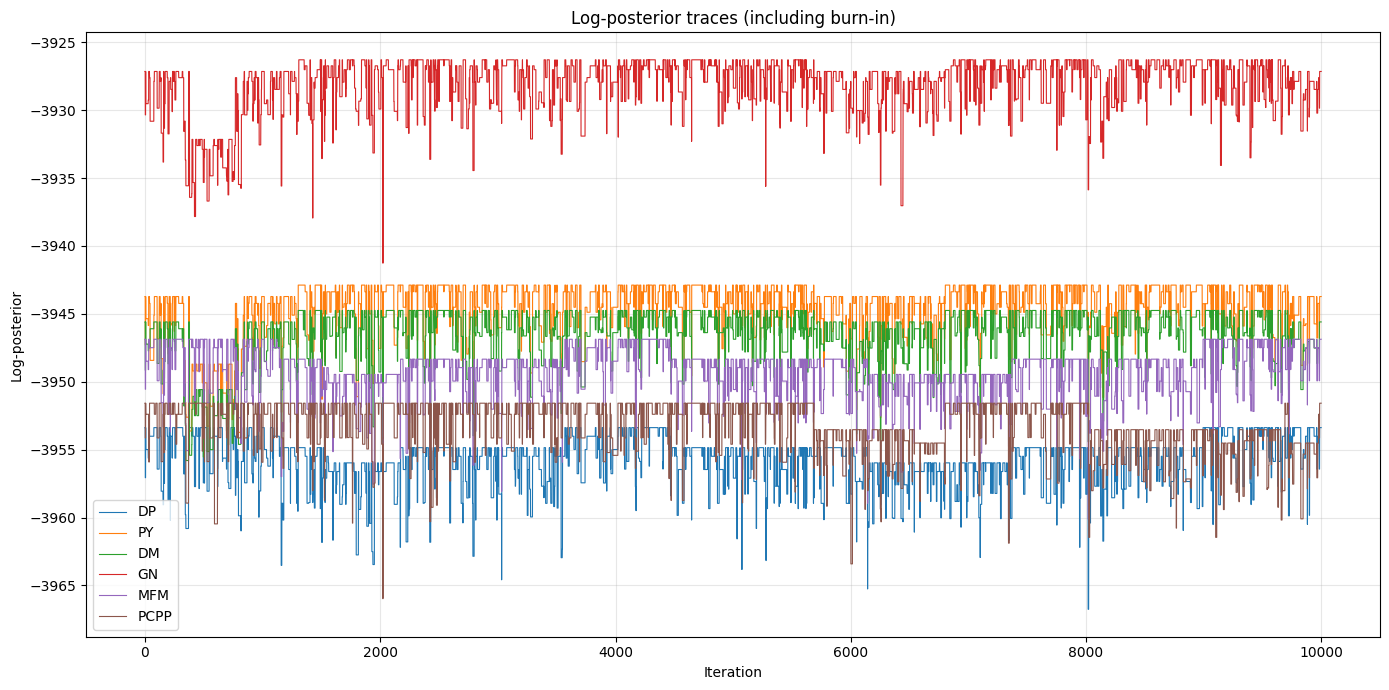

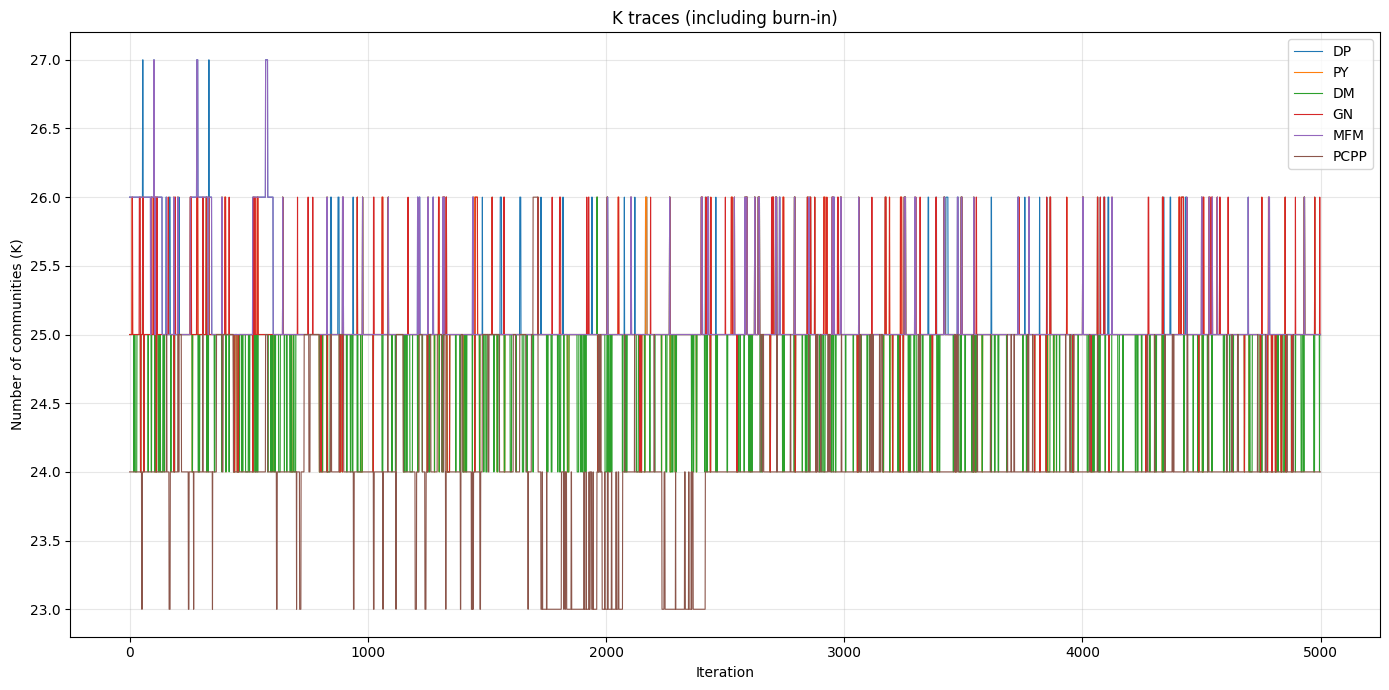

In [ ]:

# ============================================================
# 6. FULL LOG-POSTERIOR TRACE (INCLUDING BURN-IN)
# ============================================================

plt.figure(figsize=(14, 7))

for name, result in successful_results.items():

    log_posterior = np.asarray(result["log_posterior"])

    plt.plot(
        log_posterior[15000:],
        linewidth=0.8,
        label=result["prior"]
    )

plt.xlabel("Iteration")
plt.ylabel("Log-posterior")
plt.title("Log-posterior traces (including burn-in)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 7. K TRACES (INCLUDING BURN-IN)
# ============================================================

plt.figure(figsize=(14, 7))

for name, result in successful_results.items():

    K_trace = np.asarray(result["K_trace"])

    plt.plot(
        K_trace,
        linewidth=0.8,
        label=result["prior"]
    )

plt.xlabel("Iteration")
plt.ylabel("Number of communities (K)")
plt.title("K traces (including burn-in)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:

log_posterior_summary = []

for name, result in successful_results.items():

    log_posterior = np.asarray(result["log_posterior"])

    # Select iterations after 15000
    values = log_posterior[15000:]

    log_posterior_summary.append({
        "Prior": result["prior"],
        "Mean": np.mean(values),
        "Std. Dev.": np.std(values, ddof=1),
        "Median": np.median(values),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "2.5%": np.quantile(values, 0.025),
        "97.5%": np.quantile(values, 0.975)
    })


# ============================================================
# 2. CREATE SUMMARY TABLE
# ============================================================

log_posterior_table = pd.DataFrame(log_posterior_summary)

log_posterior_table = (
    log_posterior_table
    .sort_values("Mean", ascending=False)
    .reset_index(drop=True)
    .round(3)
)

display(log_posterior_table)


# ============================================================
# 3. K TRACE SUMMARY (OPTIONAL)
# ============================================================

K_trace_summary = []

for name, result in successful_results.items():

    K_trace = np.asarray(result["K_trace"])

    K_trace_summary.append({
        "Prior": result["prior"],
        "Mean K": np.mean(K_trace),
        "Std. Dev.": np.std(K_trace, ddof=1),
        "Median K": np.median(K_trace),
        "Minimum K": np.min(K_trace),
        "Maximum K": np.max(K_trace),
        "2.5%": np.quantile(K_trace, 0.025),
        "97.5%": np.quantile(K_trace, 0.975)
    })


K_trace_table = pd.DataFrame(K_trace_summary)

K_trace_table = (
    K_trace_table
    .sort_values("Mean K")
    .reset_index(drop=True)
    .round(3)
)

display(K_trace_table)

,Prior,Mean,Std. Dev.,Median,Minimum,Maximum,2.5%,97.5%
0,GN,-3928.172,2.122,-3927.601,-3941.264,-3926.292,-3934.249,-3926.292
1,PY,-3944.746,2.172,-3944.230,-3957.833,-3942.881,-3950.834,-3942.881
2,DM,-3946.618,2.145,-3946.095,-3961.144,-3944.750,-3952.497,-3944.750
3,MFM,-3949.344,1.931,-3948.959,-3960.108,-3946.869,-3953.826,-3946.869
4,PCPP,-3953.341,2.000,-3952.393,-3965.970,-3951.578,-3958.395,-3951.578
5,DP,-3955.905,1.948,-3955.487,-3966.750,-3953.376,-3960.398,-3953.376


,Prior,Mean K,Std. Dev.,Median K,Minimum K,Maximum K,2.5%,97.5%
0,PCPP,24.006,0.465,24.0,23,26,23.0,25.0
1,DM,24.866,0.378,25.0,24,26,24.0,25.0
2,PY,25.008,0.291,25.0,24,26,24.0,26.0
3,GN,25.040,0.280,25.0,24,26,25.0,26.0
4,MFM,25.091,0.299,25.0,24,27,25.0,26.0
5,DP,25.118,0.335,25.0,24,27,25.0,26.0


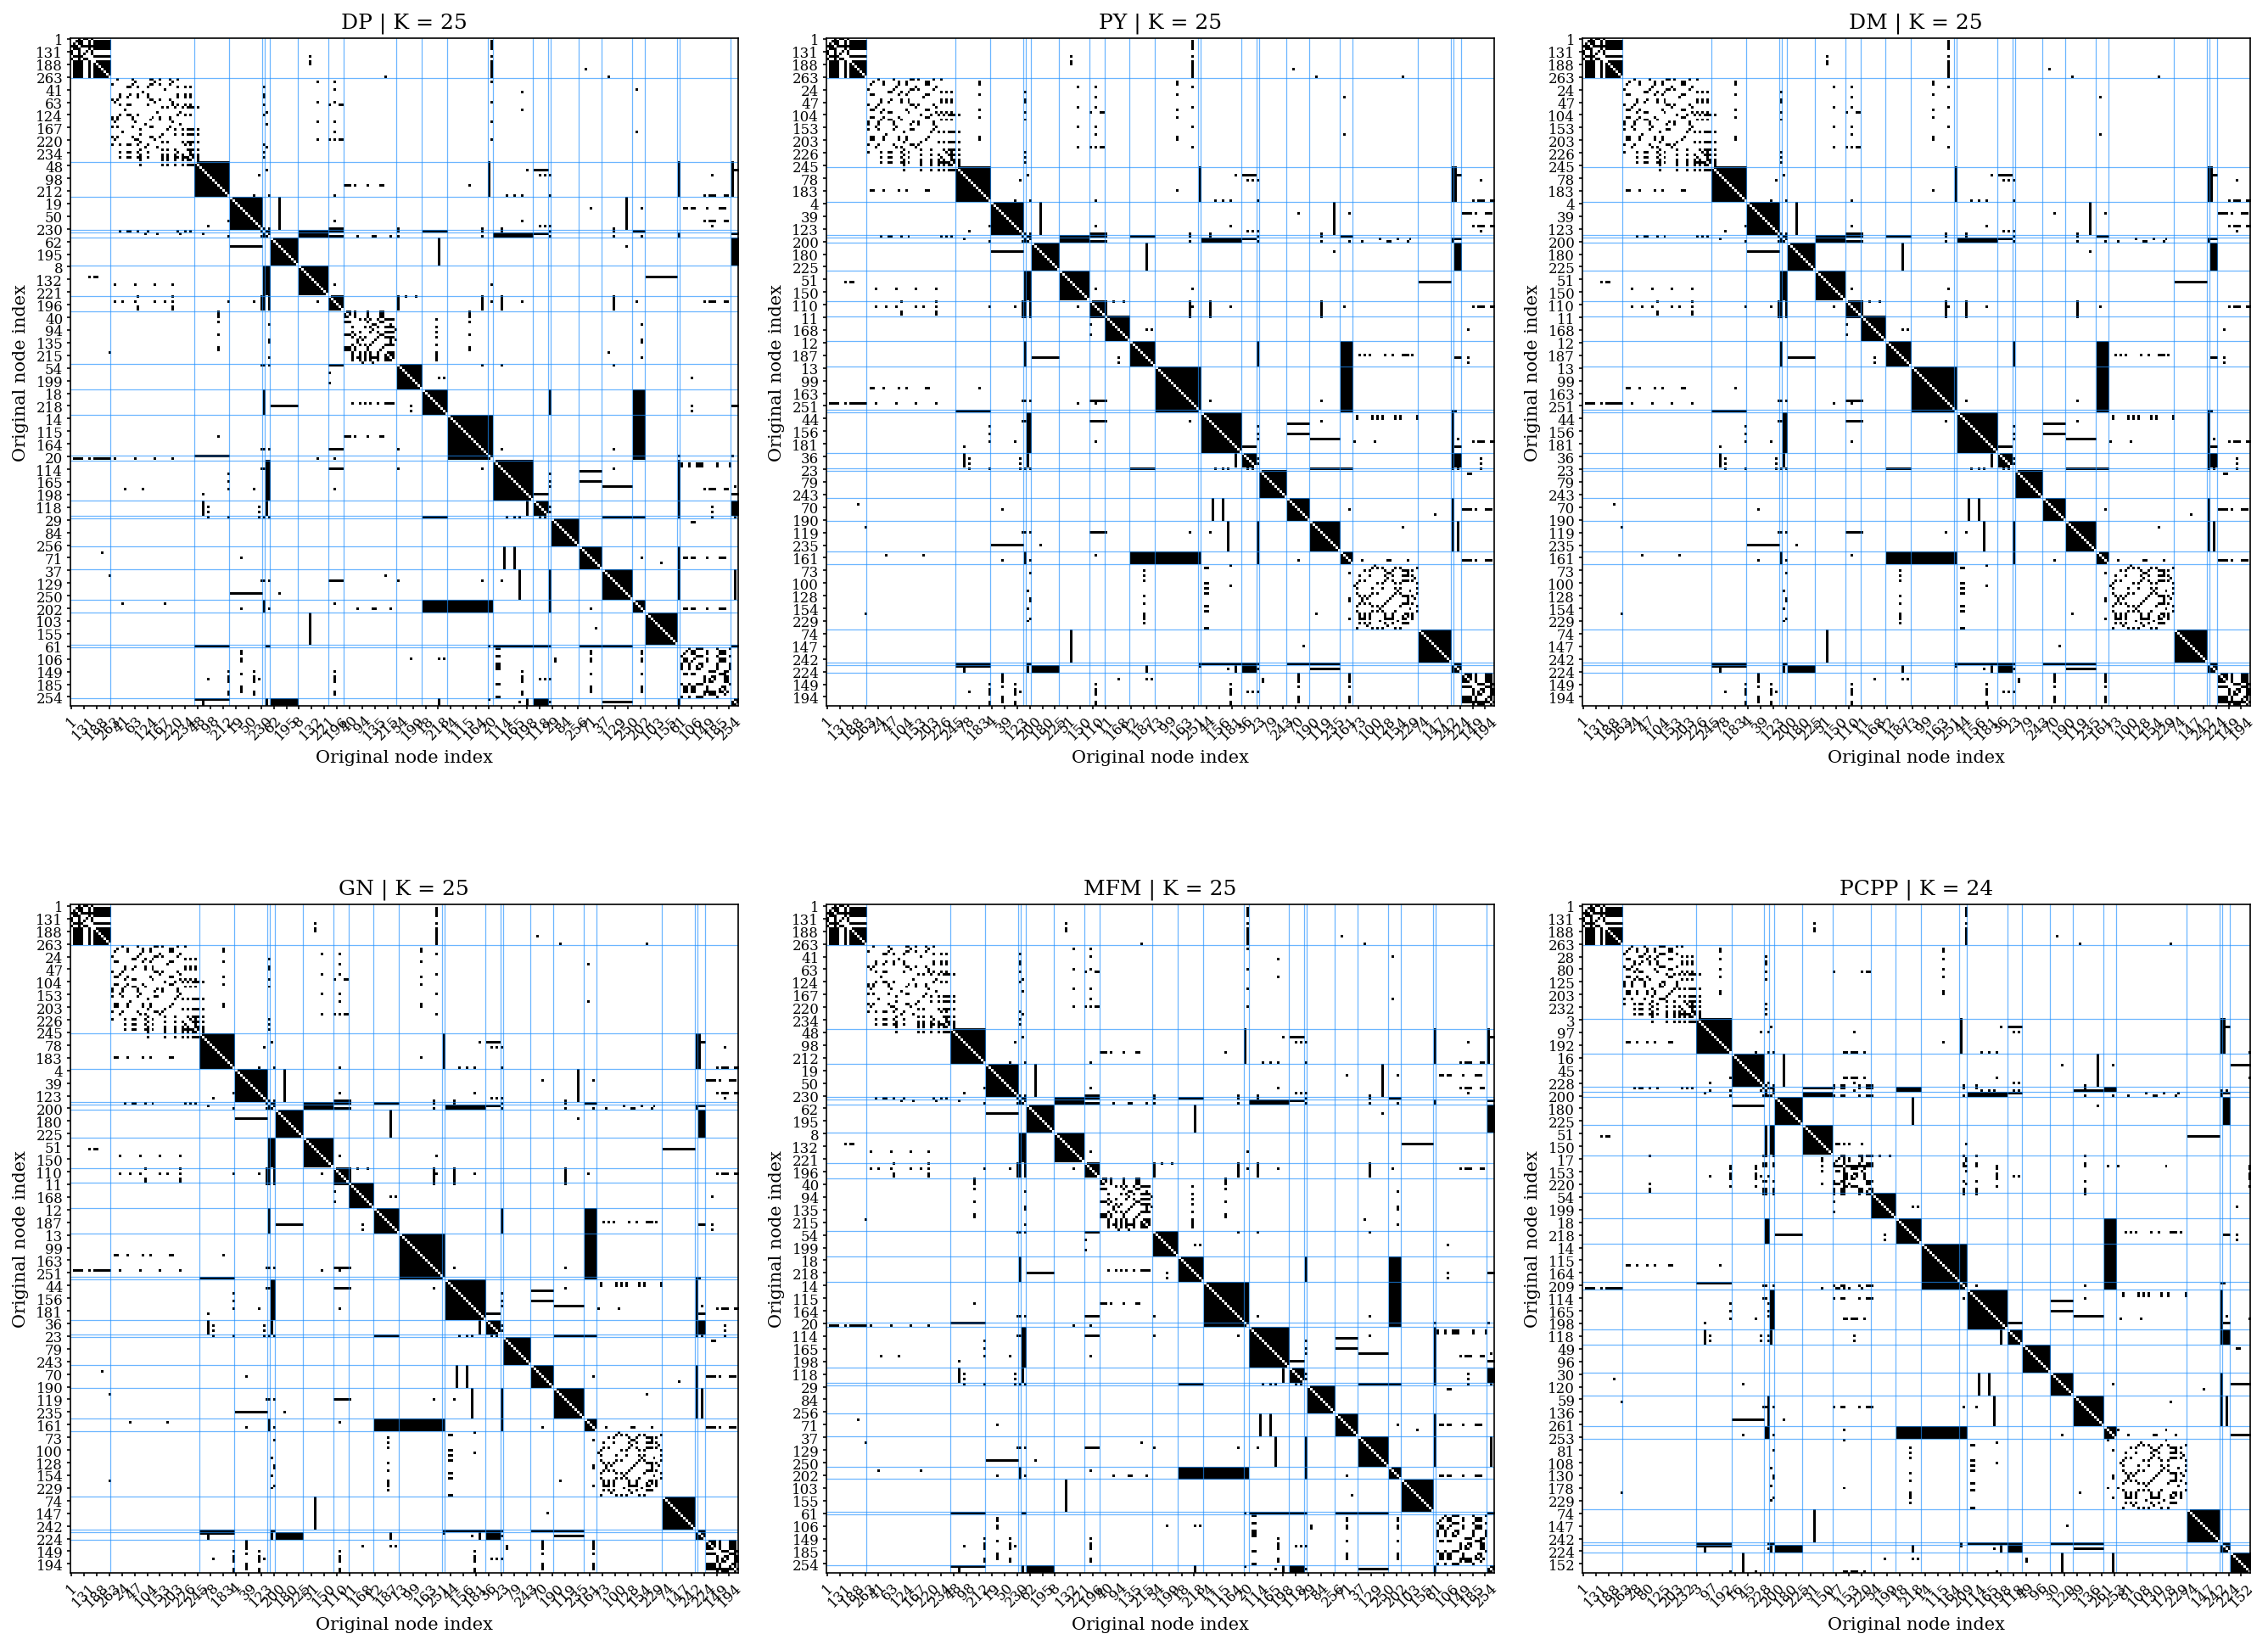

In [59]:

import numpy as np
import matplotlib.pyplot as plt

successful_results = {
    name: result
    for name, result in all_results.items()
    if result.get("status") == "success"
}


def reorder_adjacency(adjacency, labels):
    labels = np.asarray(labels)
    adjacency = np.asarray(adjacency)

    # Sort nodes according to their community labels
    order = np.argsort(labels, kind="stable")

    # Simultaneously reorder rows and columns
    A_sorted = adjacency[np.ix_(order, order)]
    sorted_labels = labels[order]

    # Identify boundaries between communities
    boundaries = np.where(
        sorted_labels[:-1] != sorted_labels[1:]
    )[0] + 1

    return A_sorted, order, boundaries


# ------------------------------------------------------------
# ADJACENCY MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 14)
)

axes = axes.flatten()

for ax, (run_name, result) in zip(
    axes, successful_results.items()
):

    # Retrieve adjacency matrix and inferred partition
    A = result["adjacency"]
    labels = result["final_partition"]

    # Check consistency
    assert A.shape[0] == len(labels), (
        f"Inconsistency in {run_name}: "
        f"matrix {A.shape} and labels {len(labels)}"
    )

    A_sorted, order, boundaries = reorder_adjacency(
        A, labels
    )

    n = A_sorted.shape[0]

    ax.imshow(
        A_sorted,
        cmap="Greys",
        interpolation="none",
        aspect="equal",
        vmin=0,
        vmax=1
    )

    # Draw separators between communities
    for boundary in boundaries:
        ax.axhline(
            boundary - 0.5,
            color="dodgerblue",
            linewidth=0.6,
            alpha=0.65
        )

        ax.axvline(
            boundary - 0.5,
            color="dodgerblue",
            linewidth=0.6,
            alpha=0.65
        )

    # Display original node indices every 5 positions
    tick_positions = np.arange(0, n, 5)

    # Recover original node numbering
    original_node_numbers = order + 1

    tick_labels = original_node_numbers[tick_positions]

    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)

    ax.set_xticklabels(
        tick_labels,
        fontsize=8,
        rotation=45
    )

    ax.set_yticklabels(
        tick_labels,
        fontsize=8
    )

    # Set title and axis labels
    prior_name = result["prior"]
    K = len(np.unique(labels))

    ax.set_title(
        f"{prior_name} | K = {K}",
        fontsize=12
    )

    ax.set_xlabel("Original node index", fontsize=10)
    ax.set_ylabel("Original node index", fontsize=10)

    ax.tick_params(
        axis="both",
        length=2,
        pad=2
    )

plt.savefig("Adjacency_inferred_partitions_Colombian_Politics.pdf",format="pdf",bbox_inches="tight")
plt.tight_layout()
plt.show()

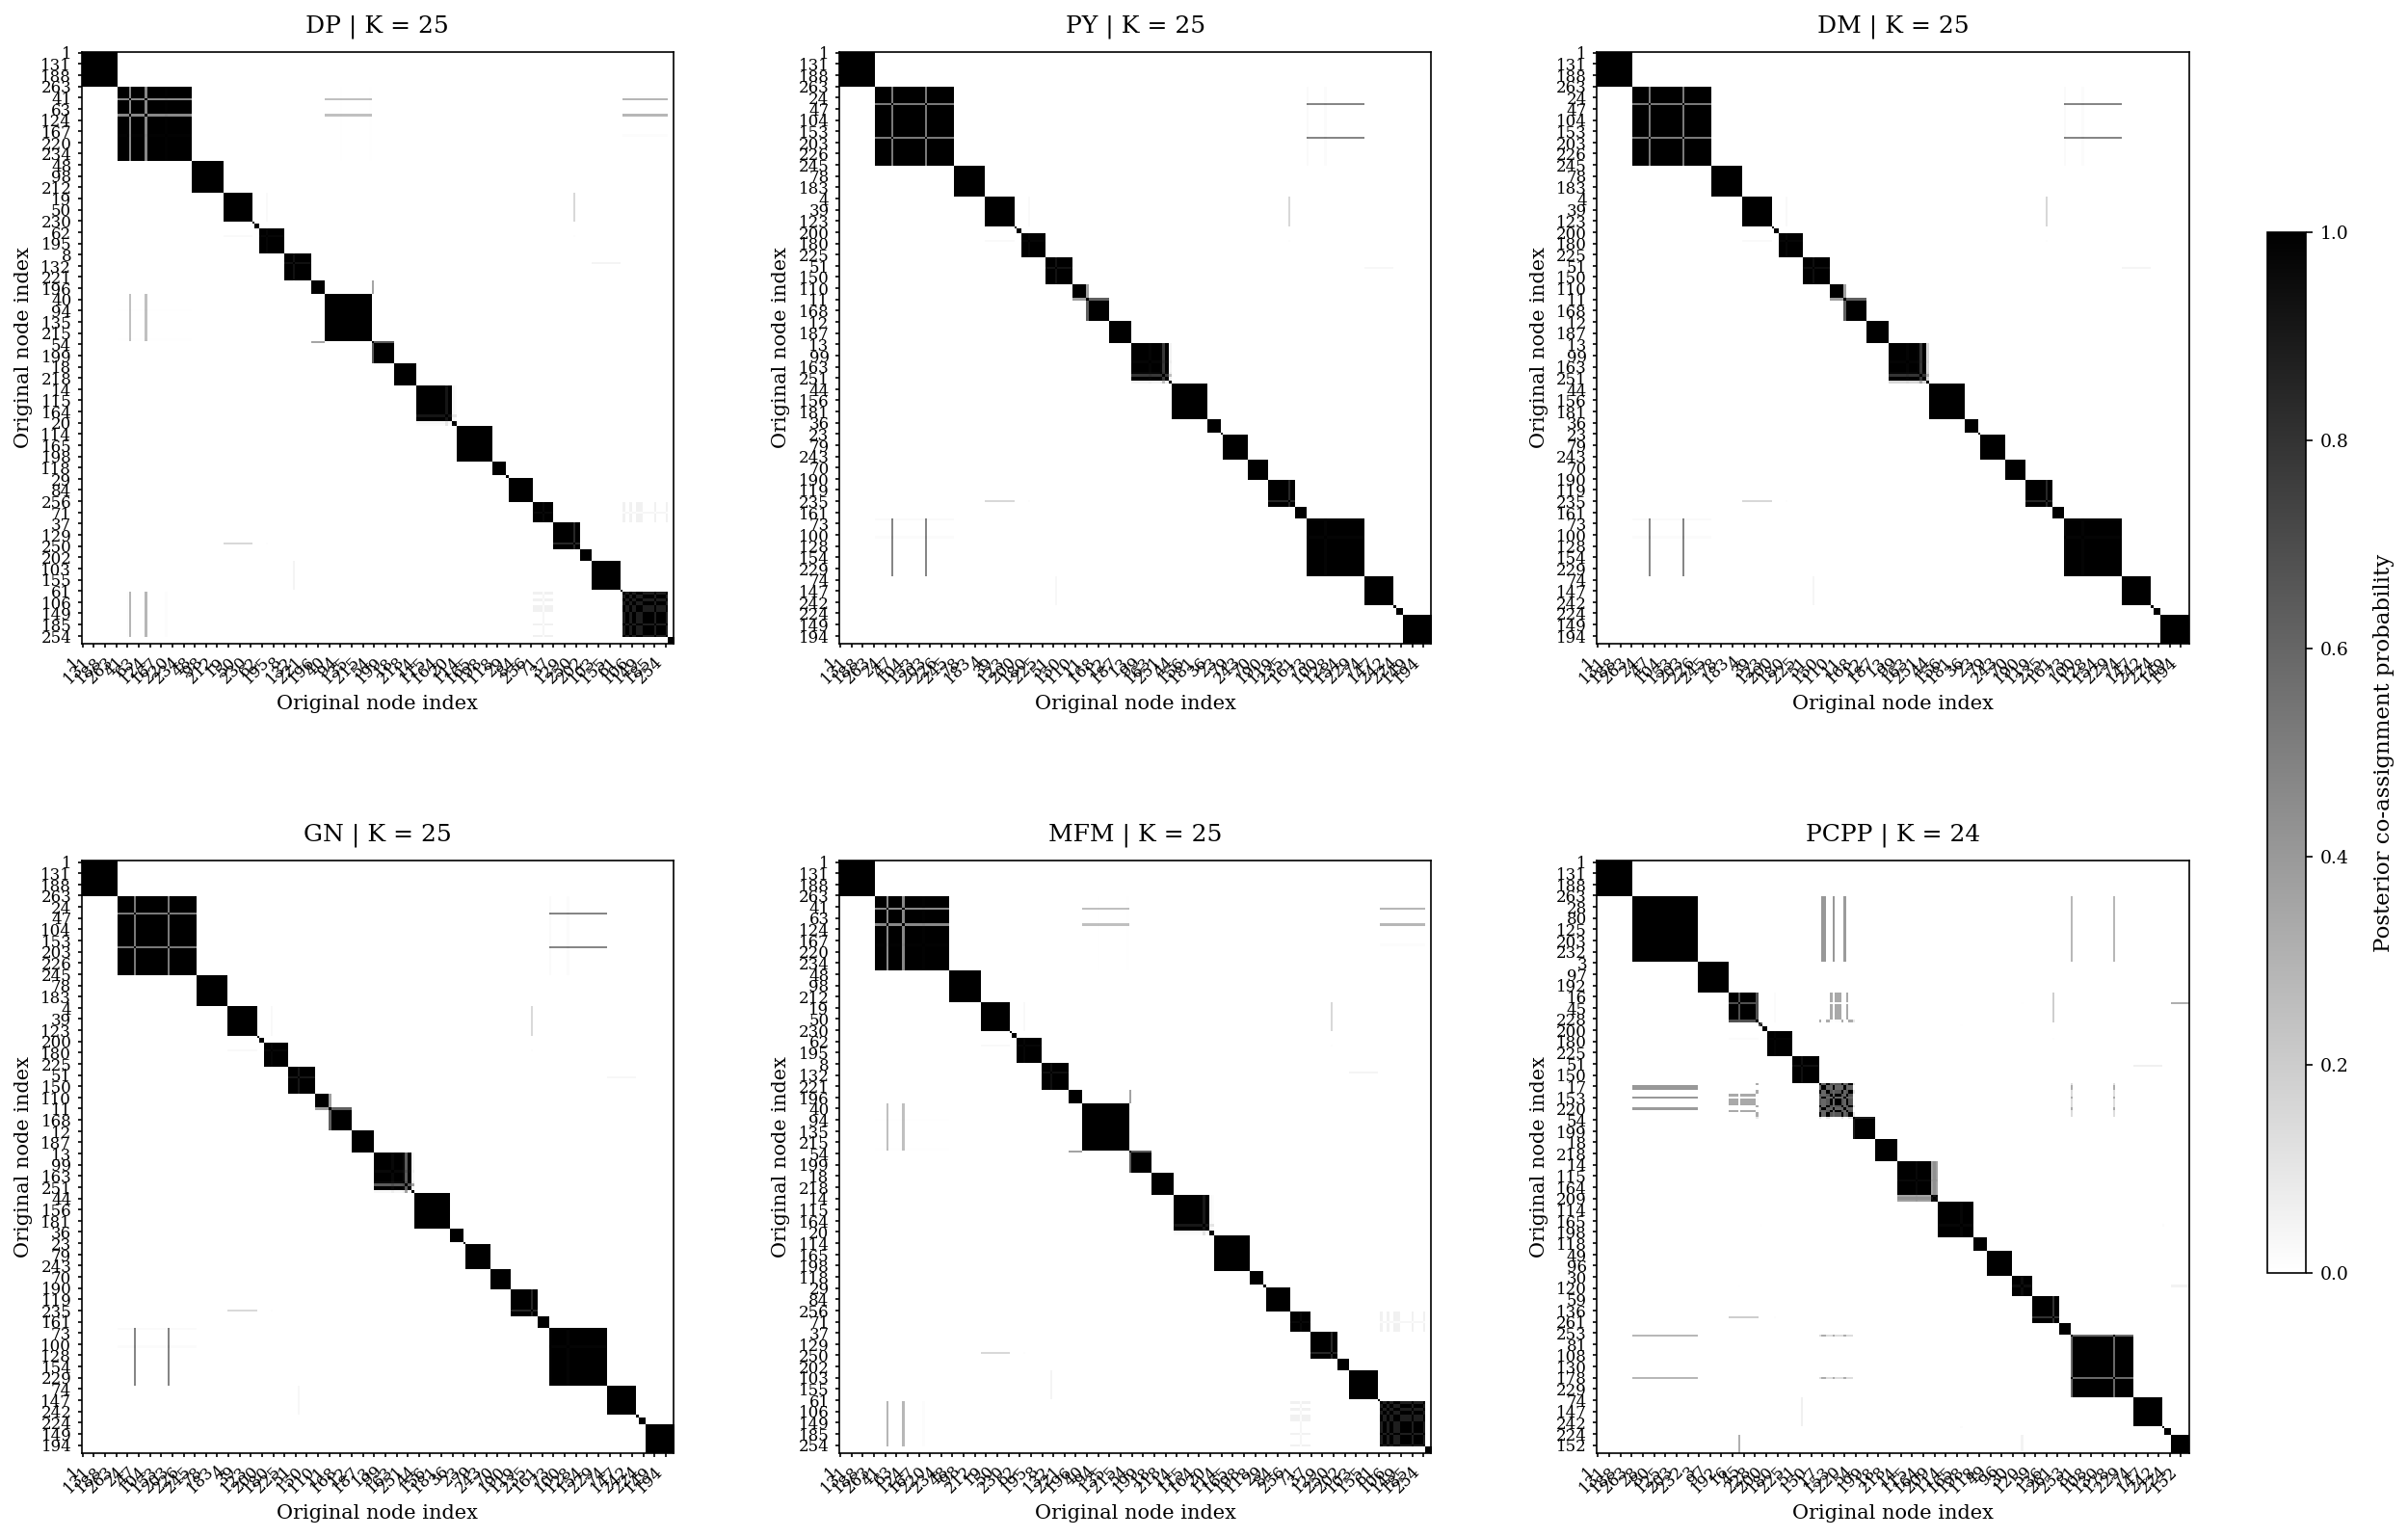

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# MCMC CONSENSUS MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12)
)

axes = axes.flatten()

# Reserve space on the right for the colorbar
fig.subplots_adjust(
    left=0.07,
    right=0.88,
    bottom=0.09,
    top=0.91,
    wspace=0.28,
    hspace=0.32
)

for ax, (run_name, result) in zip(
    axes, successful_results.items()
):

    samples = np.asarray(result["samples"])

    # samples: (n_samples, n_nodes)
    n_samples, n_nodes = samples.shape

    # Compute consensus matrix
    consensus = np.zeros(
        (n_nodes, n_nodes),
        dtype=float
    )

    for sample in samples:
        consensus += (
            sample[:, None] == sample[None, :]
        )

    consensus /= n_samples

    # Reorder nodes according to the final partition
    labels = np.asarray(result["final_partition"])
    order = np.argsort(labels, kind="stable")

    consensus_sorted = consensus[np.ix_(order, order)]

    # Plot consensus matrix
    im = ax.imshow(
        consensus_sorted,
        cmap="gray_r",
        interpolation="nearest",
        aspect="equal",
        vmin=0,
        vmax=1
    )

    # Display original node indices every 5 nodes
    tick_positions = np.arange(0, n_nodes, 5)
    original_node_numbers = order + 1
    tick_labels = original_node_numbers[tick_positions]

    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)

    ax.set_xticklabels(
        tick_labels,
        fontsize=8,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        tick_labels,
        fontsize=8
    )

    # Titles and axis labels
    K = result["K_final"]

    ax.set_title(
        f"{result['prior']} | K = {K}",
        fontsize=12,
        pad=10
    )

    ax.set_xlabel("Original node index", fontsize=10)
    ax.set_ylabel("Original node index", fontsize=10)

    ax.tick_params(
        axis="both",
        length=2,
        pad=3
    )

# ------------------------------------------------------------
# SHARED COLORBAR
# ------------------------------------------------------------

# Create a dedicated axis for the colorbar
cbar_ax = fig.add_axes([0.91, 0.20, 0.015, 0.60])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_label(
    "Posterior co-assignment probability",
    fontsize=11,
    labelpad=12
)

cbar.ax.tick_params(labelsize=9)

plt.savefig("consensus_matrices_colombian_politics.pdf",format="pdf",bbox_inches="tight")
plt.show()

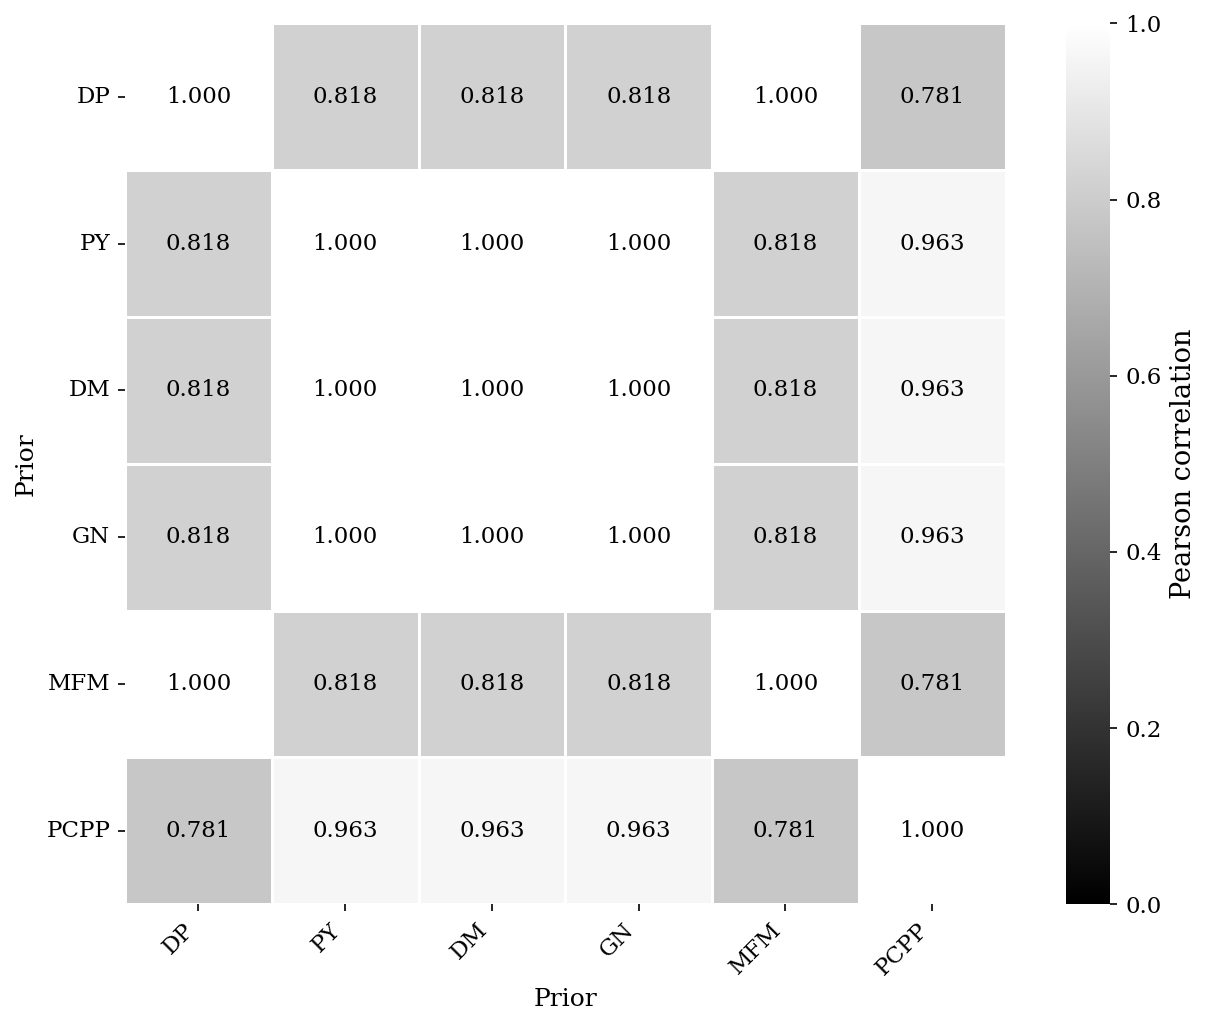

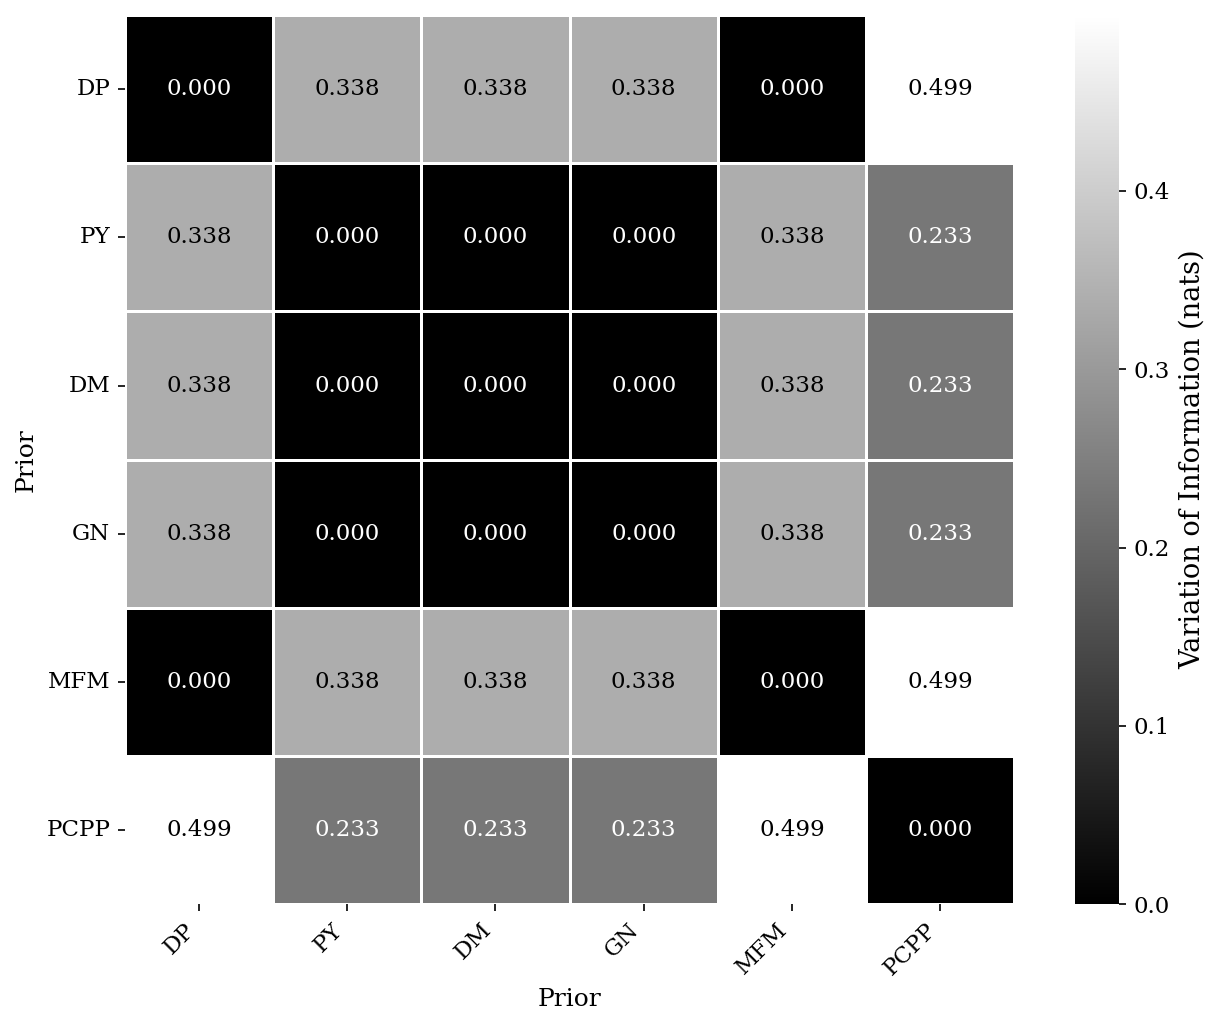

In [61]:


# ============================================================
# 1. CONSENSUS MATRICES
# ============================================================

def consensus_matrix(samples):

    samples = np.asarray(samples)
    S, n = samples.shape

    C = np.zeros((n, n), dtype=float)

    for z in samples:
        C += (z[:, None] == z[None, :])

    return C / S


consensus_matrices = {
    name: consensus_matrix(result["samples"])
    for name, result in successful_results.items()
}

prior_names = list(successful_results.keys())

# Map prior names to abbreviations
prior_abbreviations = {
    "politica_colombiana_DP": "DP",
    "politica_colombiana_PY": "PY",
    "politica_colombiana_DM": "DM",
    "politica_colombiana_GN": "GN",
    "politica_colombiana_MFM": "MFM",
    "politica_colombiana_PCPP": "PCPP"
}

# ============================================================
# 2. CORRELATION BETWEEN CONSENSUS MATRICES
# ============================================================

n_nodes = next(
    iter(successful_results.values())
)["adjacency"].shape[0]

upper_idx = np.triu_indices(n_nodes, k=1)

consensus_similarity = pd.DataFrame(
    index=prior_names,
    columns=prior_names,
    dtype=float
)

for p1 in prior_names:
    for p2 in prior_names:

        C1 = consensus_matrices[p1]
        C2 = consensus_matrices[p2]

        x = C1[upper_idx]
        y = C2[upper_idx]

        consensus_similarity.loc[p1, p2] = np.corrcoef(
            x, y
        )[0, 1]

# Apply abbreviations AFTER calculating the matrix
consensus_similarity = consensus_similarity.rename(
    index=prior_abbreviations,
    columns=prior_abbreviations
)

# ============================================================
# 3. CONSENSUS MATRIX CORRELATION HEATMAP
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    consensus_similarity,
    annot=True,
    fmt=".3f",
    cmap="gray",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Pearson correlation"
    },
    annot_kws={
        "fontsize": 11
    },
    ax=ax
)

# Adjust annotation colors according to background intensity
for text in ax.texts:
    value = float(text.get_text())
    text.set_color("white" if value < 0.5 else "black")

ax.set_xlabel("Prior", fontsize=12)
ax.set_ylabel("Prior", fontsize=12)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=11
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=11
)

plt.tight_layout()
plt.savefig("consensus_correlation_colombian_politics.pdf",format="pdf",bbox_inches="tight")
plt.show()


# ============================================================
# 4. VARIATION OF INFORMATION BETWEEN FINAL PARTITIONS
# ============================================================

from sklearn.metrics.cluster import contingency_matrix

def variation_of_information(labels1, labels2):

    contingency = contingency_matrix(labels1, labels2)

    contingency = contingency.astype(float)
    n = contingency.sum()

    # Joint and marginal probabilities
    Pxy = contingency / n
    Px = Pxy.sum(axis=1)
    Py = Pxy.sum(axis=0)

    # Entropies
    Hx = -np.sum(Px[Px > 0] * np.log(Px[Px > 0]))
    Hy = -np.sum(Py[Py > 0] * np.log(Py[Py > 0]))

    # Mutual information
    nz = Pxy > 0

    PxPy = np.outer(Px, Py)

    MI = np.sum(
        Pxy[nz] * np.log(Pxy[nz] / PxPy[nz])
    )

    # Variation of Information
    VI = Hx + Hy - 2 * MI

    return np.maximum(VI,0)


VI_matrix = pd.DataFrame(
    index=prior_names,
    columns=prior_names,
    dtype=float
)

for p1 in prior_names:
    for p2 in prior_names:

        z1 = successful_results[p1]["final_partition"]
        z2 = successful_results[p2]["final_partition"]

        VI_matrix.loc[p1, p2] = variation_of_information(
            z1, z2
        )

# Apply abbreviations
VI_matrix = VI_matrix.rename(
    index=prior_abbreviations,
    columns=prior_abbreviations
)


# ============================================================
# 5. VARIATION OF INFORMATION HEATMAP
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

# Set color scale according to the maximum VI value
vmax = VI_matrix.to_numpy().max()

sns.heatmap(
    VI_matrix,
    annot=True,
    fmt=".3f",
    cmap="gray",
    vmin=0,
    vmax=vmax,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Variation of Information (nats)"
    },
    annot_kws={
        "fontsize": 11
    },
    ax=ax
)

# Adjust annotation colors according to background intensity
threshold = vmax / 2

for text in ax.texts:
    value = float(text.get_text())

    text.set_color(
        "white" if value < threshold else "black"
    )

ax.set_xlabel("Prior", fontsize=12)
ax.set_ylabel("Prior", fontsize=12)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=11
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=11
)

plt.tight_layout()
plt.savefig("VI_heatmap_colombian_politics.pdf",format="pdf",bbox_inches="tight")
plt.show()

In [ ]:

import numpy as np
import blockdynamicnetworks as bdn

# ============================================================
# 1. RECONSTRUCT THE NETWORK
# ============================================================

first_result = next(iter(successful_results.values()))

A = np.asarray(first_result["adjacency"])
n = A.shape[0]

G_bdn = bdn.Graph(n)

for i in range(n):
    for j in range(i + 1, n):
        if A[i, j] != 0:
            G_bdn.add_edge(i, j)


# ============================================================
# 2. RECONSTRUCT THE PRIOR
# ============================================================

def reconstruct_prior(result):

    prior_name = result["prior"]
    params = result["prior_parameters"]

    if prior_name == "DP":

        return bdn.PartitionPrior(
            alpha=params["alpha"]
        )

    elif prior_name == "PY":

        return bdn.PartitionPrior(
            type=bdn.PriorType.PY,
            alpha=params["alpha"],
            sigma=params["sigma"]
        )

    elif prior_name == "DM":

        return bdn.PartitionPrior(
            type=bdn.PriorType.DM,
            beta=params["beta"],
            H_total=params["H"]
        )

    elif prior_name == "GN":

        return bdn.PartitionPrior(
            type=bdn.PriorType.GN,
            gamma=params["gamma"]
        )

    elif prior_name == "MFM":

        return bdn.PartitionPrior(
            type=bdn.PriorType.MFM,
            rho=params["rho"],
            p_k=np.asarray(params["p_k"]).tolist()
        )

    elif prior_name == "PCPP":

        return bdn.PartitionPrior(
            type=bdn.PriorType.PCPP,
            theta=params["theta"],
            omega=params["omega"],
            pcpp_tol=params["pcpp_tol"]
        )

    else:
        raise ValueError(f"Unknown prior: {prior_name}")

# ============================================================
# 3. COMPUTE LOG-LIKELIHOOD TRACES
# ============================================================

log_likelihood_traces = {}

for name, result in successful_results.items():

    prior_name = result["prior"]

    print(f"Computing log-likelihood: {prior_name}")

    # Reconstruct prior and posterior model
    prior = reconstruct_prior(result)

    model = bdn.PosteriorModel(
        G_bdn,
        prior,
        1.0,
        1.0
    )

    samples = np.asarray(result["samples"])

    likelihood_values = []

    for labels in samples:

        partition = bdn.Partition(
            labels.tolist()
        )

        log_likelihood = model.log_likelihood(
            partition
        )

        likelihood_values.append(log_likelihood)

    log_likelihood_traces[prior_name] = np.asarray(
        likelihood_values
    )

print("\nAll log-likelihood traces computed successfully.")

import numpy as np
import pandas as pd

# Calculate descriptive statistics for each prior
summary = []

for prior, values in log_likelihood_traces.items():
    values = np.asarray(values)[2500:]

    summary.append({
        "Prior": prior,
        "Mean": np.mean(values),
        "Std. Dev.": np.std(values, ddof=1),
        "Median": np.median(values),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "2.5%": np.quantile(values, 0.025),
        "97.5%": np.quantile(values, 0.975)
    })

# Create summary table
log_likelihood_summary = pd.DataFrame(summary)

# Format numerical values
log_likelihood_summary = log_likelihood_summary.round(3)

display(log_likelihood_summary)

Computing log-likelihood: DP
Computing log-likelihood: PY
Computing log-likelihood: DM
Computing log-likelihood: GN
Computing log-likelihood: MFM
Computing log-likelihood: PCPP

All log-likelihood traces computed successfully.


,Prior,Mean,Std. Dev.,Median,Minimum,Maximum,2.5%,97.5%
0,DP,-3178.794,1.907,-3177.921,-3189.166,-3177.075,-3184.396,-3177.075
1,PY,-3168.517,2.248,-3167.424,-3182.656,-3165.924,-3174.465,-3165.924
2,DM,-3168.969,2.753,-3167.424,-3187.638,-3165.924,-3175.533,-3165.924
3,GN,-3168.300,2.239,-3167.424,-3182.656,-3165.924,-3174.465,-3165.924
4,MFM,-3178.711,1.817,-3177.921,-3189.166,-3177.075,-3184.332,-3177.075
5,PCPP,-3162.845,2.166,-3162.319,-3175.911,-3155.861,-3167.574,-3157.726


In [55]:
import numpy as np
import pandas as pd
from scipy.special import logsumexp

def calculate_waic_fast(adjacency, samples, a=1.0, b=1.0, max_samples=500):

    n = adjacency.shape[0]

    # Identify all undirected node pairs
    upper_i, upper_j = np.triu_indices(n, k=1)
    y = adjacency[upper_i, upper_j].astype(float)

    n_dyads = len(y)

    # Select posterior samples
    if len(samples) > max_samples:
        indices = np.linspace(
            0, len(samples) - 1, max_samples, dtype=int
        )
        samples = samples[indices]

    S = len(samples)

    # Online accumulation
    log_sum_exp = np.full(n_dyads, -np.inf)
    mean_ll = np.zeros(n_dyads)
    M2 = np.zeros(n_dyads)

    rng = np.random.default_rng(123)

    for s, labels in enumerate(samples, start=1):

        # Relabel communities consecutively
        _, z = np.unique(labels, return_inverse=True)
        K = len(np.unique(z))

        # Identify the block pair for each dyad
        block_min = np.minimum(z[upper_i], z[upper_j])
        block_max = np.maximum(z[upper_i], z[upper_j])

        codes = block_min * K + block_max

        # Group dyads by block pair
        _, inverse = np.unique(codes, return_inverse=True)

        n_pairs = inverse.max() + 1

        counts = np.bincount(inverse, minlength=n_pairs)
        successes = np.bincount(
            inverse, weights=y, minlength=n_pairs
        )

        failures = counts - successes

        # Sample block probabilities from their Beta posteriors
        p = rng.beta(
            a + successes,
            b + failures
        )

        # Pointwise log-likelihood
        ll = (
            y * np.log(p[inverse])
            + (1 - y) * np.log1p(-p[inverse])
        )

        # Update log-sum-exp
        log_sum_exp = np.logaddexp(log_sum_exp, ll)

        # Update mean and variance using Welford's algorithm
        delta = ll - mean_ll
        mean_ll += delta / s
        M2 += delta * (ll - mean_ll)

    # WAIC components
    lppd = np.sum(log_sum_exp - np.log(S))
    p_waic = np.sum(M2 / (S - 1))

    waic = -2 * (lppd - p_waic)

    return {
        "WAIC": waic,
        "lppd": lppd,
        "p_WAIC": p_waic,
        "Samples": S
    }


# Calculate WAIC for all six priors
waic_results = []

for prior in ["DP", "PY", "DM", "GN", "MFM", "PCPP"]:

    key = f"politica_colombiana_{prior}"
    result = successful_results[key]

    metrics = calculate_waic_fast(
        adjacency=np.asarray(result["adjacency"]),
        samples=np.asarray(result["samples"]),
        a=1.0,
        b=1.0,
        max_samples=2500
    )

    waic_results.append({
        "Prior": prior,
        **metrics
    })


# Create comparison table
waic_table = pd.DataFrame(waic_results)

waic_table = (
    waic_table
    .sort_values("WAIC")
    .reset_index(drop=True)
    .round(3)
)

display(waic_table)

,Prior,WAIC,lppd,p_WAIC,Samples
0,DP,4738.469,-2198.064,171.170,2500
1,PY,4739.330,-2206.635,163.029,2500
2,GN,4739.865,-2201.421,168.511,2500
3,MFM,4740.682,-2199.853,170.488,2500
4,DM,4762.766,-2210.836,170.547,2500
5,PCPP,4933.346,-2173.251,293.423,2500
